In [ ]:

import pandas as pd
from google.colab import files

uploaded = files.upload()


Saving united_kingdom_contracts_finder_releases_2025.xlsx to united_kingdom_contracts_finder_releases_2025.xlsx


In [ ]:

filename = "united_kingdom_contracts_finder_releases_2025.xlsx"

df = pd.read_excel(
    filename,
    sheet_name="main",
    nrows=5
)

display(df[[
    "buyer_name",
    "tender_title",
    "tender_value_amount"
]])


,buyer_name,tender_title,tender_value_amount
0,Shropshire Council,RMCV 039 - Apprenticeship Levy Training Provid...,469128.00
1,Leicestershire County Council,S660-Mainstream Taxi - The Cedars Academy,49.98
2,Central Bedfordshire Council,CBC-1811-T-SM Domestic Ground Floor Extension ...,NaN
3,BISHOP WILKINSON CATHOLIC EDUCATION TRUST,Home to School Transport,2270000.00
4,UK SHARED BUSINESS SERVICES LIMITED,Ceramic Frames for the repair of SP1 Doublet.,10383.00


In [ ]:

excel_file = pd.ExcelFile(filename)

print("Available Excel sheets:")
print(excel_file.sheet_names)


Available Excel sheets:
['main', 'awards', 'awards_documents', 'awards_suppliers', 'parties', 'tender_items', 'tender_items_deliveryaddresses', 'tender_documents', 'tende_additionalclassifications', 'planning_documents', 'planning_milestones', 'planning_budget_budgetbreakdown', 'relatedprocesses']


In [ ]:

awards = pd.read_excel(
    filename,
    sheet_name="awards",
    nrows=5
)

suppliers = pd.read_excel(
    filename,
    sheet_name="awards_suppliers",
    nrows=5
)

print("AWARD DATA COLUMNS:")
print(awards.columns.tolist())

print("\nSUPPLIER DATA COLUMNS:")
print(suppliers.columns.tolist())



AWARD DATA COLUMNS:
['id', 'date', 'datePublished', 'status', 'value_amount', 'value_currency', 'contractPeriod_endDate', 'contractPeriod_startDate', 'main_ocid', 'main_id', 'description']

SUPPLIER DATA COLUMNS:
['id', 'name', 'main_ocid', 'main_id', 'awards_id']


In [ ]:

# Load all award records
awards = pd.read_excel(
    filename,
    sheet_name="awards",
    usecols=["id", "main_ocid", "value_amount", "value_currency"]
)

# Load all supplier records
suppliers = pd.read_excel(
    filename,
    sheet_name="awards_suppliers",
    usecols=["awards_id", "main_ocid", "name"]
)

# Merge suppliers with their awards
merged = suppliers.merge(
    awards,
    left_on=["awards_id", "main_ocid"],
    right_on=["id", "main_ocid"],
    how="left",
    indicator=True
)

# Check matching results
print("Total supplier records:", len(suppliers))
print("Matched records:", (merged["_merge"] == "both").sum())
print("Unmatched records:", (merged["_merge"] == "left_only").sum())

print("\nSample supplier awards:")
display(merged[[
    "name",
    "value_amount",
    "value_currency"
]].head(10))


Total supplier records: 57583
Matched records: 57583
Unmatched records: 0

Sample supplier awards:


,name,value_amount,value_currency
0,Riverside Training,469128.0,GBP
1,Let Me Play LTD,469128.0,GBP
2,JGA LTD,469128.0,GBP
3,"Institute of Revenues, Rating and Valuation",469128.0,GBP
4,Riverside Training,469128.0,GBP
5,MBKB LTD,469128.0,GBP
6,QDOS Training,469128.0,GBP
7,Juniper Training,469128.0,GBP
8,County Training HLC,469128.0,GBP
9,Barnsley College,469128.0,GBP


In [ ]:

print("Total records:", len(merged))

print("\nMatching results:")
print(merged["_merge"].value_counts())

print("\nMissing values:")
print(merged[["name", "value_amount", "value_currency"]].isnull().sum())

print("\nCurrencies:")
print(merged["value_currency"].value_counts(dropna=False))

print("\nDuplicate records:", merged.duplicated().sum())


Total records: 57583

Matching results:
_merge
both          57583
left_only         0
right_only        0
Name: count, dtype: int64

Missing values:
name              62
value_amount       0
value_currency     0
dtype: int64

Currencies:
value_currency
GBP    57583
Name: count, dtype: int64

Duplicate records: 121


In [ ]:

supplier_data = merged.drop_duplicates().copy()

supplier_data["name"] = (
    supplier_data["name"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

supplier_counts = (
    supplier_data
    .groupby(["main_ocid", "awards_id"], dropna=False)["name"]
    .nunique()
)

print("Unique awards:", len(supplier_counts))
print("Single-supplier awards:", (supplier_counts == 1).sum())
print("Multiple-supplier awards:", (supplier_counts > 1).sum())
print("Awards without a named supplier:", (supplier_counts == 0).sum())


Unique awards: 43767
Single-supplier awards: 42242
Multiple-supplier awards: 1464
Awards without a named supplier: 61


In [ ]:

single_keys = (
    supplier_counts[supplier_counts == 1]
    .reset_index()[["main_ocid", "awards_id"]]
)

clean_awards = supplier_data.merge(
    single_keys,
    on=["main_ocid", "awards_id"],
    how="inner"
)

clean_awards = clean_awards.drop_duplicates(
    subset=["main_ocid", "awards_id"]
).copy()

clean_awards["value_amount"] = pd.to_numeric(
    clean_awards["value_amount"],
    errors="coerce"
)

clean_awards = clean_awards[
    (clean_awards["value_amount"] > 0) &
    (clean_awards["value_currency"] == "GBP")
].copy()

print("Clean award records:", len(clean_awards))
print("Unique suppliers:", clean_awards["name"].nunique())
print("Total award value (GBP):", f"{clean_awards['value_amount'].sum():,.2f}")

display(clean_awards[["name", "value_amount"]].head(10))


Clean award records: 41233
Unique suppliers: 19763
Total award value (GBP): 401,280,266,251.52


,name,value_amount
0,TAKE ME SERVICE LTD T/A ADT TAXIS,9496.00
1,Precision Ceramics Ltd,10383.00
2,CAUSEWAY TECHNOLOGIES LIMITED,110572.62
4,Prosci UK Ltd,52480.00
5,Francotyp - Postalia LTD,26400.00
6,Gadsby and Fay,62489.00
7,James Robertshaw,21578.00
8,Simmons & Simmons Llp,47500.00
9,Eunomia Research and Consulting Ltd,153159.24
10,Perk UK Ltd,2800000.00


In [ ]:

print("Award Value Distribution (GBP):")
print(
    clean_awards["value_amount"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

print("\nAwards over £1 billion:")
print((clean_awards["value_amount"] > 1_000_000_000).sum())

print("\nTop 10 Highest-Value Awards:")
display(
    clean_awards.nlargest(
        10, "value_amount"
    )[["name", "value_amount", "main_ocid"]]
)


Award Value Distribution (GBP):
count    4.123300e+04
mean     9.732017e+06
std      3.793423e+08
min      1.000000e-02
50%      9.020000e+04
90%      1.465140e+06
95%      4.192654e+06
99%      3.706723e+07
max      3.500000e+10
Name: value_amount, dtype: float64

Awards over £1 billion:
36

Top 10 Highest-Value Awards:


,name,value_amount,main_ocid
15429,A list of successful suppliers can be found in...,3.500000e+10,ocds-b5fd17-71ce599c-844c-4747-bc72-9f8d5c8c8dee
15430,A list of successful suppliers can be found in...,3.500000e+10,ocds-b5fd17-71ce599c-844c-4747-bc72-9f8d5c8c8dee
13523,A list of successful suppliers can be found in...,2.500000e+10,ocds-b5fd17-43877340-e4a2-4dc8-a6f0-eff3a2ce794a
27634,MJ Church (Plant) Ltd,2.119100e+10,ocds-b5fd17-99bb6876-019a-4d3a-a3ec-b4e43f9aade4
36944,SEE Services,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36945,BSN Group Construction,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36946,BSN Group Construction,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36947,Carson Powell Construction Ltd,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36948,RenEnergy Ltd,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
12651,A list of successful suppliers can be found in...,1.250000e+10,ocds-b5fd17-2f43bc95-8740-4528-8c4b-76489dc710fc


In [ ]:

placeholder_mask = clean_awards["name"].str.contains(
    "list of successful suppliers|suppliers can be found",
    case=False,
    na=False
)

high_value = clean_awards[
    clean_awards["value_amount"] > 1_000_000_000
]

print("Placeholder supplier records:", placeholder_mask.sum())

print(
    "Placeholder award value (GBP):",
    f"{clean_awards.loc[placeholder_mask, 'value_amount'].sum():,.2f}"
)

print("\nHigh-value awards:", len(high_value))
print("Unique procurement processes:", high_value["main_ocid"].nunique())

print("\nHigh-value awards by procurement process:")
display(
    high_value.groupby("main_ocid")
    .agg(
        award_count=("awards_id", "nunique"),
        total_value=("value_amount", "sum")
    )
    .sort_values("total_value", ascending=False)
    .head(10)
)


Placeholder supplier records: 23
Placeholder award value (GBP): 157,722,038,571.00

High-value awards: 36
Unique procurement processes: 30

High-value awards by procurement process:


,award_count,total_value
main_ocid,,
ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0,5,9.000000e+10
ocds-b5fd17-71ce599c-844c-4747-bc72-9f8d5c8c8dee,2,7.000000e+10
ocds-b5fd17-43877340-e4a2-4dc8-a6f0-eff3a2ce794a,1,2.500000e+10
ocds-b5fd17-99bb6876-019a-4d3a-a3ec-b4e43f9aade4,1,2.119100e+10
ocds-b5fd17-b21b338f-5d0a-4d73-9fbd-fd14950291bb,2,2.000000e+10
ocds-b5fd17-2f43bc95-8740-4528-8c4b-76489dc710fc,1,1.250000e+10
ocds-b5fd17-7e5fe33e-0830-4db9-99c3-9d8165e1a3de,1,1.200000e+10
ocds-b5fd17-089071a7-26c2-492f-b4a9-e0a689a5f882,1,6.500000e+09
ocds-b5fd17-02d75d7e-429c-42a1-a972-a02c5976e8ec,1,6.373000e+09


In [ ]:

analysis_awards = clean_awards.loc[~placeholder_mask].copy()

analysis_awards["supplier_name"] = (
    analysis_awards["name"]
    .astype("string")
    .str.strip()
)

analysis_awards = analysis_awards.dropna(
    subset=["supplier_name"]
)

analysis_awards = analysis_awards[
    analysis_awards["supplier_name"] != ""
].copy()

print("Records after cleaning:", len(analysis_awards))
print("Unique supplier names:", analysis_awards["supplier_name"].nunique())
print("Removed placeholder records:", len(clean_awards) - len(analysis_awards))

print("\nRemaining awards above £1 billion:")
print((analysis_awards["value_amount"] > 1_000_000_000).sum())

print("\nTop 10 remaining awards:")
display(
    analysis_awards.nlargest(10, "value_amount")[
        ["supplier_name", "value_amount", "main_ocid"]
    ]
)


Records after cleaning: 41210
Unique supplier names: 19760
Removed placeholder records: 23

Remaining awards above £1 billion:
22

Top 10 remaining awards:


,supplier_name,value_amount,main_ocid
27634,MJ Church (Plant) Ltd,2.119100e+10,ocds-b5fd17-99bb6876-019a-4d3a-a3ec-b4e43f9aade4
36944,SEE Services,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36945,BSN Group Construction,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36946,BSN Group Construction,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36947,Carson Powell Construction Ltd,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36948,RenEnergy Ltd,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
18050,A successful supplier list can be found in the...,1.000000e+10,ocds-b5fd17-b21b338f-5d0a-4d73-9fbd-fd14950291bb
18051,A successful supplier list can be found in the...,1.000000e+10,ocds-b5fd17-b21b338f-5d0a-4d73-9fbd-fd14950291bb
176,Please see webpage for Contract Award Details,6.000000e+09,ocds-b5fd17-048c1f74-0848-4907-9083-53afdb659faf
16302,GXO,4.200000e+09,ocds-b5fd17-86d78415-5cc4-42bf-8165-c1c6c42d05d5


In [ ]:

invalid_patterns = (
    r"successful supplier list|"
    r"list of successful suppliers|"
    r"supplier list can be found|"
    r"please see webpage|"
    r"contract award details"
)

invalid_mask = analysis_awards["supplier_name"].str.contains(
    invalid_patterns,
    case=False,
    na=False,
    regex=True
)

print("Potential invalid supplier records:", invalid_mask.sum())

print("\nPotential invalid supplier names:")
display(
    analysis_awards.loc[invalid_mask, "supplier_name"]
    .value_counts()
    .head(20)
)

print("\nAssociated award value (GBP):")
print(f"£{analysis_awards.loc[invalid_mask, 'value_amount'].sum():,.2f}")


Potential invalid supplier records: 3

Potential invalid supplier names:


,count
supplier_name,
A successful supplier list can be found in the attachments area,2
Please see webpage for Contract Award Details,1



Associated award value (GBP):
£26,000,000,000.00


In [ ]:

analysis_awards = analysis_awards.loc[~invalid_mask].copy()

print("Remaining award records:", len(analysis_awards))
print("Unique supplier names:", analysis_awards["supplier_name"].nunique())

print("\nTotal recorded award value (GBP):")
print(f"£{analysis_awards['value_amount'].sum():,.2f}")

print("\nTop 10 highest-value awards:")
display(
    analysis_awards.nlargest(10, "value_amount")[
        ["supplier_name", "value_amount", "main_ocid"]
    ]
)


Remaining award records: 41207
Unique supplier names: 19758

Total recorded award value (GBP):
£217,558,227,680.52

Top 10 highest-value awards:


,supplier_name,value_amount,main_ocid
27634,MJ Church (Plant) Ltd,2.119100e+10,ocds-b5fd17-99bb6876-019a-4d3a-a3ec-b4e43f9aade4
36944,SEE Services,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36945,BSN Group Construction,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36946,BSN Group Construction,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36947,Carson Powell Construction Ltd,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
36948,RenEnergy Ltd,1.800000e+10,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
16302,GXO,4.200000e+09,ocds-b5fd17-86d78415-5cc4-42bf-8165-c1c6c42d05d5
14211,RADIOCOMS SYSTEMS LIMITED,4.107287e+09,ocds-b5fd17-541df742-fc36-4ec2-966f-a9eda2f2f40f
10484,2020 Delivery Ltd.,4.000000e+09,ocds-b5fd17-fbe61758-3dee-4698-947a-f04aa2adf933
36406,PHOENIX SOFTWARE LIMITED,2.220000e+09,ocds-b5fd17-72d227e5-bb1b-48b5-9559-936c8af69e3d


In [ ]:

repeated_values = (
    analysis_awards
    .groupby(["main_ocid", "value_amount"])
    .agg(
        award_count=("awards_id", "nunique"),
        supplier_count=("supplier_name", "nunique")
    )
    .reset_index()
)

suspicious_awards = repeated_values[
    (repeated_values["award_count"] > 1) &
    (repeated_values["value_amount"] >= 100_000_000)
].copy()

print("Processes with repeated high award values:")
print(len(suspicious_awards))

display(
    suspicious_awards
    .sort_values("value_amount", ascending=False)
    .head(15)
)


Processes with repeated high award values:
7


,main_ocid,value_amount,award_count,supplier_count
20428,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0,1.800000e+10,5,4
38255,ocds-b5fd17-f25cf6c9-bef9-45d4-8404-71b1fb1491f1,9.370000e+08,2,2
19814,ocds-b5fd17-7cc6fefb-e6f6-4d19-af23-31ec3c59e3f6,4.400000e+08,2,1
33244,ocds-b5fd17-d1d0f6ea-5607-4d5b-ad15-4dbaaf9a59a0,4.000000e+08,2,1
39328,ocds-b5fd17-f98c1453-609a-4b13-ac3f-9f3a966bbf79,3.070000e+08,3,1
27587,ocds-b5fd17-ae47cb08-660f-4ba3-8f14-06f16b84eaf6,2.888473e+08,2,1
28060,ocds-b5fd17-b0e92646-01c7-477a-84a3-1f634ee95925,1.241280e+08,8,1


In [ ]:

target_ocid = suspicious_awards.loc[
    suspicious_awards["value_amount"].idxmax(), "main_ocid"
]

award_details = pd.read_excel(
    filename,
    sheet_name="awards",
    usecols=["id", "main_ocid", "description", "status"]
)

target_details = analysis_awards.loc[
    analysis_awards["main_ocid"] == target_ocid,
    ["awards_id", "supplier_name", "value_amount"]
].merge(
    award_details[award_details["main_ocid"] == target_ocid],
    left_on="awards_id",
    right_on="id",
    how="left"
)

pd.set_option("display.max_colwidth", 150)

display(
    target_details[
        ["awards_id", "supplier_name", "value_amount", "status", "description"]
    ]
)


,awards_id,supplier_name,value_amount,status,description
0,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0-1,SEE Services,1.800000e+10,active,NaN
1,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0-2,BSN Group Construction,1.800000e+10,active,NaN
2,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0-3,BSN Group Construction,1.800000e+10,active,NaN
3,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0-4,Carson Powell Construction Ltd,1.800000e+10,active,NaN
4,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0-5,RenEnergy Ltd,1.800000e+10,active,NaN


In [ ]:

main_columns = pd.read_excel(
    filename, sheet_name="main", nrows=0
).columns.tolist()

key = next(
    (c for c in ["ocid", "main_ocid"] if c in main_columns),
    None
)

fields = [
    "buyer_name",
    "tender_title",
    "tender_description",
    "tender_value_amount",
    "tender_procurementMethodDetails"
]

selected = [c for c in fields if c in main_columns]

if key:
    main_details = pd.read_excel(
        filename,
        sheet_name="main",
        usecols=[key] + selected
    )

    display(
        main_details.loc[
            main_details[key] == target_ocid,
            [key] + selected
        ].T
    )
else:
    print("Available columns:")
    print(main_columns)


,40200
ocid,ocds-b5fd17-80a84b6c-c775-4044-9c1a-fef8552f90c0
buyer_name,The Crescent Academy
tender_title,GEM (Good Estate Management) Framework
tender_description,The GEM (Good Estate Management) Framework has been specifically designed to help educational settings with professional schools' procurement and ...
tender_value_amount,18000000000.0
tender_procurementMethodDetails,Open procedure


In [ ]:

tender_info = main_details[
    ["ocid", "buyer_name", "tender_title", "tender_value_amount"]
].drop_duplicates(subset=["ocid"])

analysis_with_tenders = analysis_awards.merge(
    tender_info,
    left_on="main_ocid",
    right_on="ocid",
    how="left",
    validate="many_to_one"
)

framework_mask = analysis_with_tenders["tender_title"].str.contains(
    r"\bframework\b|\bDPS\b|dynamic purchasing system",
    case=False,
    na=False,
    regex=True
)

print("Framework-related award records:", framework_mask.sum())
print("Other award records:", (~framework_mask).sum())

print("\nTop 10 framework-related awards:")
display(
    analysis_with_tenders.loc[framework_mask]
    .nlargest(10, "value_amount")[
        ["buyer_name", "tender_title", "supplier_name", "value_amount"]
    ]
)


Framework-related award records: 1842
Other award records: 39365

Top 10 framework-related awards:


,buyer_name,tender_title,supplier_name,value_amount
35996,The Crescent Academy,GEM (Good Estate Management) Framework,SEE Services,1.800000e+10
35997,The Crescent Academy,GEM (Good Estate Management) Framework,BSN Group Construction,1.800000e+10
35998,The Crescent Academy,GEM (Good Estate Management) Framework,BSN Group Construction,1.800000e+10
35999,The Crescent Academy,GEM (Good Estate Management) Framework,Carson Powell Construction Ltd,1.800000e+10
36000,The Crescent Academy,GEM (Good Estate Management) Framework,RenEnergy Ltd,1.800000e+10
40034,Ministry of Justice,Call Off Contract for Workforce Solutions Framework (RM6288),Alexander Mann Solutions,1.382449e+09
37837,British Telecommunications plc,GIS Programme - Cross-Regional Supplier Framework (Type C)),British Telecommunications plc,8.000000e+08
9950,Defra Commercial,RM6288 Workforce Solutions Framework (Contingent Labour PSR),Alexander Mann Solutions,7.392000e+08
13977,SALISBURY NHS FOUNDATION TRUST,"(AWARD, Opportunity now closed) S10353 Apprenticeships Training & End Point Framework, Final Opening Feb 25",Suppliers as listed on attached Excel document,5.000000e+08
21542,Darlington Borough Council,Framework Agreement for Joint Venture Residential Development with Darlington Borough Council - P2017/1190/NE & PB2021-00346,Esh Homes Limited,3.000000e+08


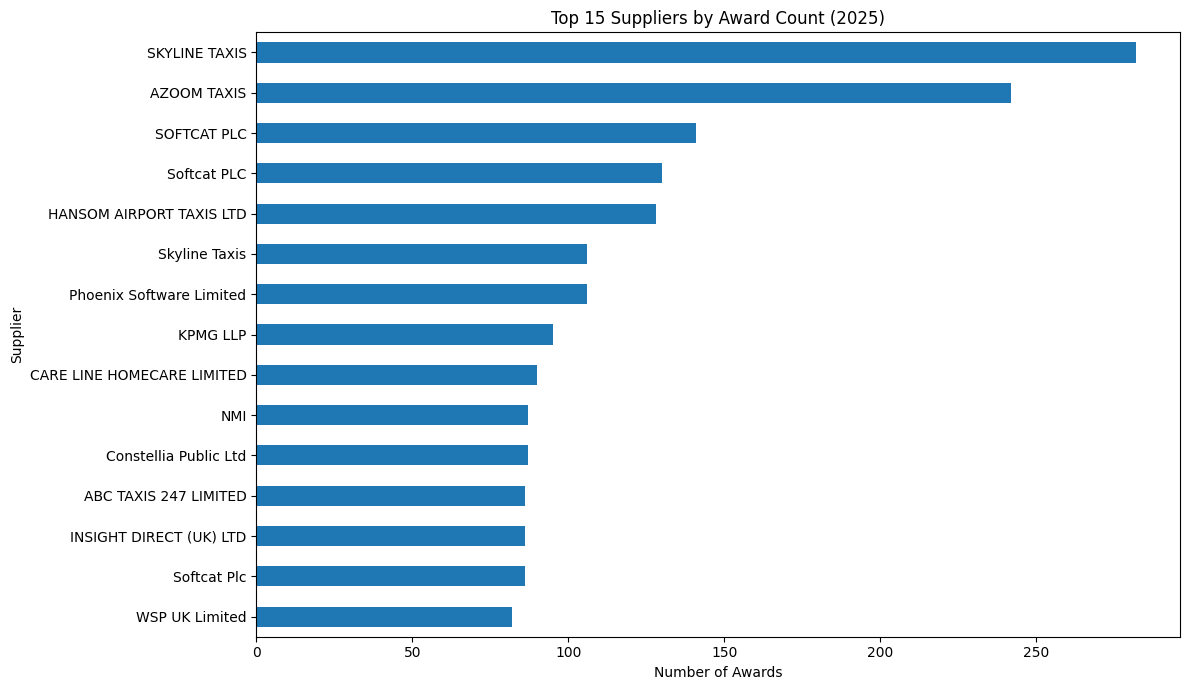

Records included: 39363


In [ ]:

import matplotlib.pyplot as plt

invalid_names = (
    r"suppliers? as listed|"
    r"supplier list|"
    r"list of successful suppliers|"
    r"suppliers? can be found|"
    r"please see webpage|"
    r"attached excel document"
)

valid_awards = analysis_with_tenders[
    ~framework_mask &
    ~analysis_with_tenders["supplier_name"].str.contains(
        invalid_names, case=False, na=False
    )
].copy()

top_suppliers = (
    valid_awards.groupby("supplier_name")["awards_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(12, 7))
top_suppliers.plot(kind="barh")

plt.title("Top 15 Suppliers by Award Count (2025)")
plt.xlabel("Number of Awards")
plt.ylabel("Supplier")
plt.tight_layout()
plt.show()

print("Records included:", len(valid_awards))


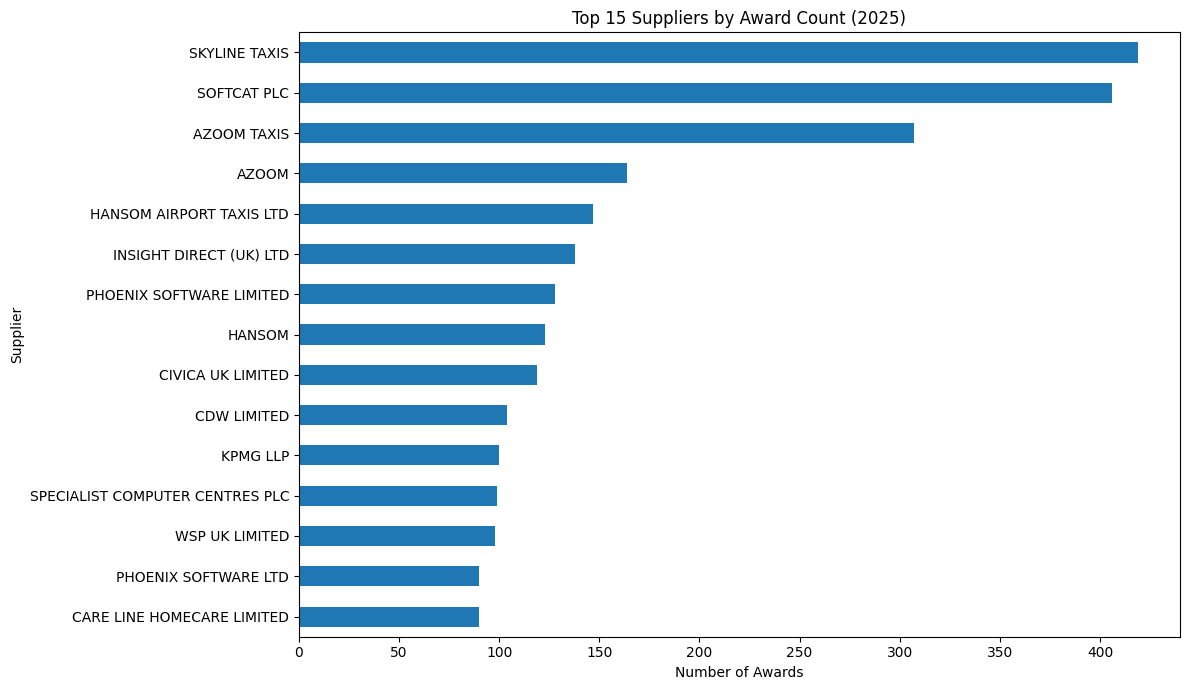

Unique supplier names before: 19079
Unique supplier names after: 17341


In [ ]:

valid_awards["supplier_clean"] = (
    valid_awards["supplier_name"]
    .astype("string")
    .str.upper()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

top_suppliers_clean = (
    valid_awards.groupby("supplier_clean")["awards_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(12, 7))
top_suppliers_clean.plot(kind="barh")

plt.title("Top 15 Suppliers by Award Count (2025)")
plt.xlabel("Number of Awards")
plt.ylabel("Supplier")
plt.tight_layout()
plt.show()

print("Unique supplier names before:",
      valid_awards["supplier_name"].nunique())

print("Unique supplier names after:",
      valid_awards["supplier_clean"].nunique())


In [ ]:

buyer_supplier = (
    valid_awards
    .dropna(subset=["buyer_name", "supplier_clean", "awards_id"])
    .groupby(["buyer_name", "supplier_clean"])["awards_id"]
    .nunique()
    .reset_index(name="award_count")
)

buyer_supplier["buyer_total"] = (
    buyer_supplier.groupby("buyer_name")["award_count"]
    .transform("sum")
)

buyer_supplier["award_share"] = (
    buyer_supplier["award_count"] / buyer_supplier["buyer_total"]
)

buyer_concentration = (
    buyer_supplier.groupby("buyer_name")
    .agg(
        total_awards=("buyer_total", "first"),
        unique_suppliers=("supplier_clean", "nunique"),
        top_supplier_share=("award_share", "max"),
        hhi=("award_share", lambda x: (x ** 2).sum())
    )
    .reset_index()
)

buyer_concentration = buyer_concentration[
    (buyer_concentration["total_awards"] >= 20) &
    (buyer_concentration["unique_suppliers"] >= 3)
].copy()

buyer_concentration["top_supplier_share"] *= 100

print("Buyers included:", len(buyer_concentration))

display(
    buyer_concentration.sort_values(
        "top_supplier_share", ascending=False
    ).head(10).round(3)
)


Buyers included: 375


,buyer_name,total_awards,unique_suppliers,top_supplier_share,hhi
664,Gloucestershire Health and Care NHS Foundation Trust,28,9,71.429,0.520
1377,POLICE DIGITAL SERVICE,40,14,57.500,0.354
2140,Wokingham Borough Council,116,27,38.793,0.185
603,FRIMLEY HEALTH NHS FOUNDATION TRUST,44,27,38.636,0.164
595,FCDO Services,224,59,34.821,0.146
2,7 Force Commercial Services,21,10,33.333,0.179
423,Darlington Borough Council,279,86,32.258,0.187
306,Cheshire East Borough Council,25,14,32.000,0.146
1140,NHS Digital,26,12,30.769,0.148
1341,ORBIT GROUP LIMITED,20,14,30.000,0.130


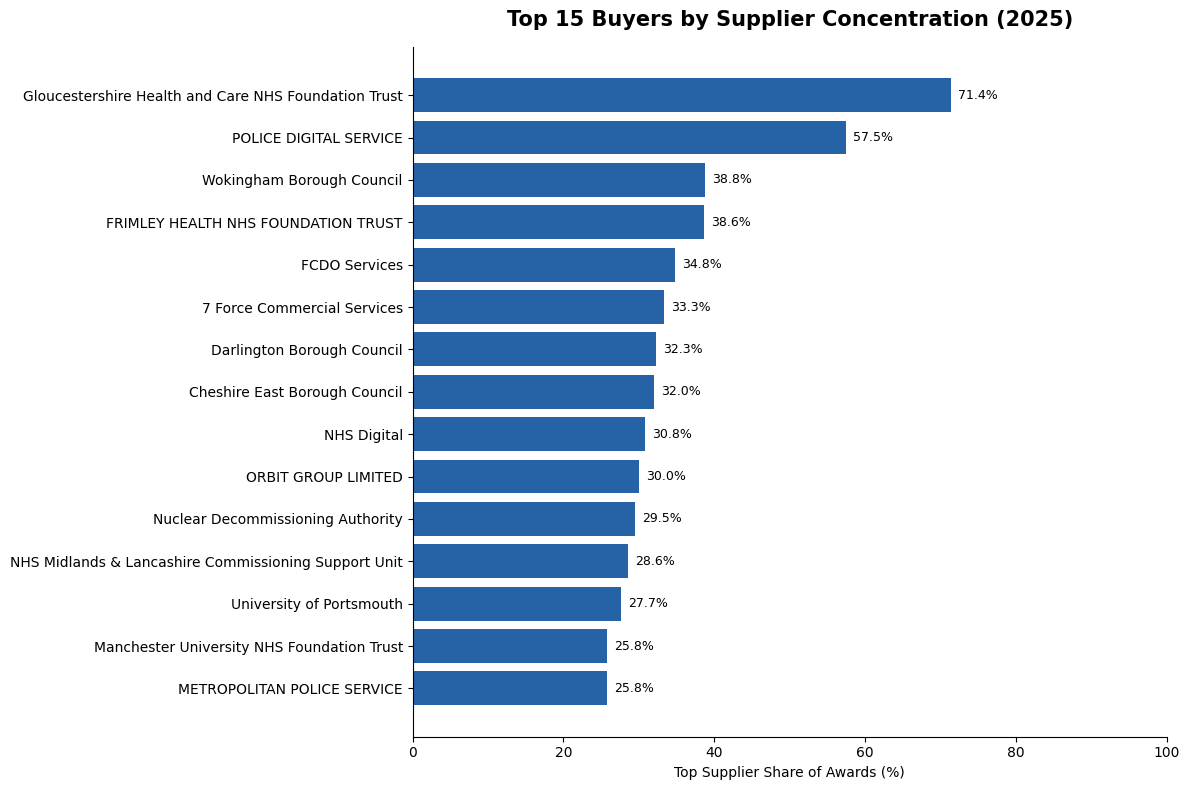

In [ ]:

top_buyers = (
    buyer_concentration
    .nlargest(15, "top_supplier_share")
    .sort_values("top_supplier_share")
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    top_buyers["buyer_name"],
    top_buyers["top_supplier_share"],
    color="#2563A6"
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=5,
    fontsize=9
)

ax.set_title(
    "Top 15 Buyers by Supplier Concentration (2025)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Top Supplier Share of Awards (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "supplier_concentration_2025.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Supplier Concentration Classification (2025)
concentration_level
Low       345
Medium     28
High        2
Name: count, dtype: int64

Percentage Distribution:
concentration_level
Low       92.00
Medium     7.47
High       0.53
Name: count, dtype: float64


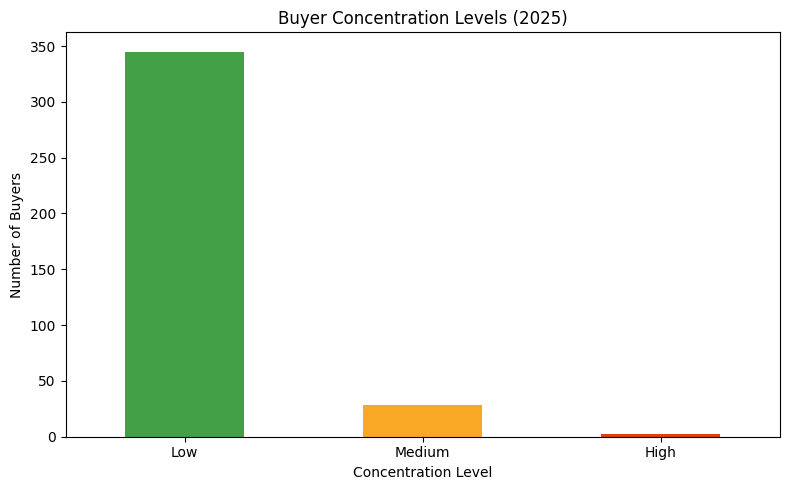

In [ ]:

import numpy as np

buyer_concentration["concentration_level"] = pd.cut(
    buyer_concentration["top_supplier_share"],
    bins=[0, 20, 40, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

risk_summary = (
    buyer_concentration["concentration_level"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
)

print("Supplier Concentration Classification (2025)")
print(risk_summary)

print("\nPercentage Distribution:")
print((risk_summary / risk_summary.sum() * 100).round(2))

plt.figure(figsize=(8, 5))
risk_summary.plot(
    kind="bar",
    color=["#43A047", "#F9A825", "#D84315"]
)

plt.title("Buyer Concentration Levels (2025)")
plt.xlabel("Concentration Level")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "buyer_concentration_levels_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

from google.colab import files

historical_files = files.upload()

print("Uploaded files:")
for file in historical_files:
    print(file)


Saving united_kingdom_contracts_finder_releases_2024.xlsx to united_kingdom_contracts_finder_releases_2024.xlsx
Saving united_kingdom_contracts_finder_releases_2023.xlsx to united_kingdom_contracts_finder_releases_2023.xlsx
Saving united_kingdom_contracts_finder_releases_2022.xlsx to united_kingdom_contracts_finder_releases_2022.xlsx
Uploaded files:
united_kingdom_contracts_finder_releases_2024.xlsx
united_kingdom_contracts_finder_releases_2023.xlsx
united_kingdom_contracts_finder_releases_2022.xlsx


In [ ]:

import os
import pandas as pd
import numpy as np

years = [2022, 2023, 2024, 2025]
year_results = []
buyer_results = []

invalid_pattern = (
    r"list of successful suppliers|successful supplier list|"
    r"suppliers? as listed|supplier list can be found|"
    r"please see webpage|contract award details|"
    r"attached excel document"
)

framework_pattern = (
    r"\bframework\b|\bDPS\b|dynamic purchasing system"
)

for year in years:
    path = f"united_kingdom_contracts_finder_releases_{year}.xlsx"

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing file: {path}")

    main = pd.read_excel(
        path,
        sheet_name="main",
        usecols=["id", "buyer_name", "tender_title"]
    ).drop_duplicates("id")

    awards = pd.read_excel(
        path,
        sheet_name="awards",
        usecols=["id", "main_id", "value_amount", "value_currency"]
    ).drop_duplicates(["main_id", "id"])

    suppliers = pd.read_excel(
        path,
        sheet_name="awards_suppliers",
        usecols=["main_id", "awards_id", "name"]
    )

    suppliers["supplier"] = (
        suppliers["name"].astype("string")
        .str.upper().str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

    suppliers = suppliers[
        suppliers["supplier"].notna() &
        ~suppliers["supplier"].str.contains(
            invalid_pattern, case=False, na=False
        )
    ].drop_duplicates(["main_id", "awards_id", "supplier"])

    supplier_counts = (
        suppliers.groupby(["main_id", "awards_id"])["supplier"]
        .nunique()
    )

    single_keys = (
        supplier_counts[supplier_counts == 1]
        .reset_index()[["main_id", "awards_id"]]
    )

    data = (
        suppliers
        .merge(single_keys, on=["main_id", "awards_id"])
        .merge(
            awards,
            left_on=["main_id", "awards_id"],
            right_on=["main_id", "id"]
        )
        .merge(
            main,
            left_on="main_id",
            right_on="id"
        )
    )

    data = data[
        (pd.to_numeric(data["value_amount"], errors="coerce") > 0) &
        (data["value_currency"] == "GBP") &
        ~data["tender_title"].str.contains(
            framework_pattern, case=False, na=False
        )
    ].copy()

    data["buyer"] = (
        data["buyer_name"].astype("string")
        .str.upper().str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

    data = data.dropna(subset=["buyer"])

    counts = (
        data.groupby(["buyer", "supplier"])
        .size()
        .reset_index(name="award_count")
    )

    counts["buyer_total"] = (
        counts.groupby("buyer")["award_count"].transform("sum")
    )

    counts["share"] = (
        counts["award_count"] / counts["buyer_total"]
    )

    buyers = (
        counts.groupby("buyer")
        .agg(
            total_awards=("buyer_total", "first"),
            unique_suppliers=("supplier", "nunique"),
            top_supplier_share=("share", "max"),
            hhi=("share", lambda x: (x ** 2).sum())
        )
        .reset_index()
    )

    buyers = buyers[
        (buyers["total_awards"] >= 20) &
        (buyers["unique_suppliers"] >= 3)
    ].copy()

    buyers["year"] = year
    buyers["top_supplier_share"] *= 100

    buyers["concentration_level"] = pd.cut(
        buyers["top_supplier_share"],
        bins=[0, 20, 40, np.inf],
        labels=["Low", "Medium", "High"],
        right=False
    )

    year_results.append({
        "Year": year,
        "Eligible_Buyers": len(buyers),
        "Low": (buyers["concentration_level"] == "Low").sum(),
        "Medium": (buyers["concentration_level"] == "Medium").sum(),
        "High": (buyers["concentration_level"] == "High").sum(),
        "Average_HHI": buyers["hhi"].mean()
    })

    buyer_results.append(buyers)
    print(f"{year}: Analysis completed")

year_summary = pd.DataFrame(year_results)
buyer_year = pd.concat(buyer_results, ignore_index=True)

display(year_summary.round(3))


2022: Analysis completed
2023: Analysis completed
2024: Analysis completed
2025: Analysis completed


,Year,Eligible_Buyers,Low,Medium,High,Average_HHI
0,2022,386,368,17,1,0.037
1,2023,444,423,19,2,0.037
2,2024,451,431,16,4,0.036
3,2025,374,347,25,2,0.043


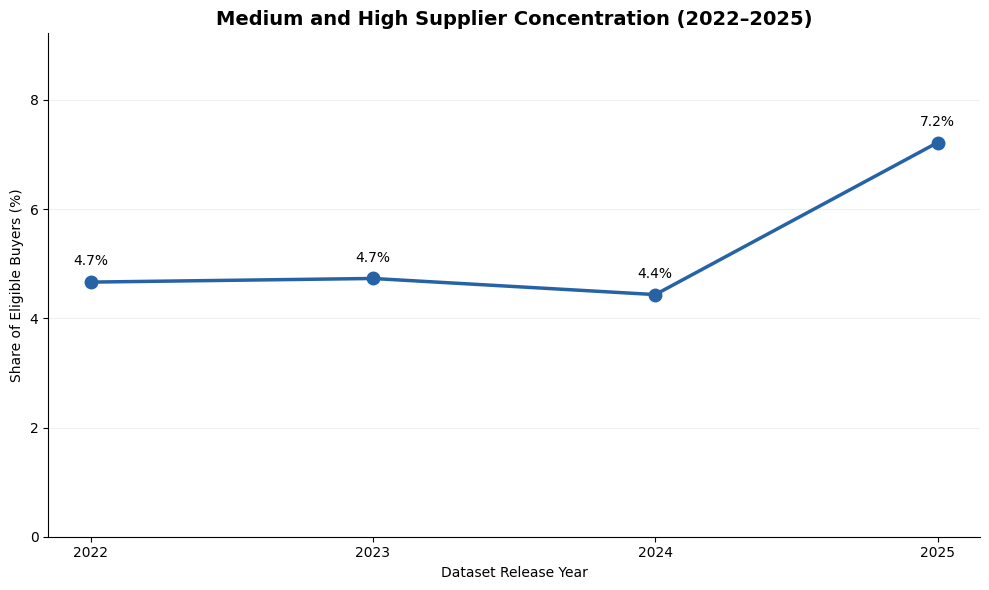

In [ ]:

year_summary["Medium_High_Pct"] = (
    (year_summary["Medium"] + year_summary["High"])
    / year_summary["Eligible_Buyers"] * 100
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    year_summary["Year"],
    year_summary["Medium_High_Pct"],
    marker="o",
    markersize=9,
    linewidth=2.5,
    color="#2563A6"
)

for year, value in zip(
    year_summary["Year"],
    year_summary["Medium_High_Pct"]
):
    ax.annotate(
        f"{value:.1f}%",
        (year, value),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

ax.set_title(
    "Medium and High Supplier Concentration (2022–2025)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Dataset Release Year")
ax.set_ylabel("Share of Eligible Buyers (%)")
ax.set_xticks(year_summary["Year"])
ax.set_ylim(0, max(year_summary["Medium_High_Pct"]) + 2)
ax.grid(axis="y", alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "supplier_concentration_trend_2022_2025.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:

year_summary["Total_Classified"] = (
    year_summary["Low"] +
    year_summary["Medium"] +
    year_summary["High"]
)

year_summary["Medium_High_Pct"] = (
    (year_summary["Medium"] + year_summary["High"])
    / year_summary["Eligible_Buyers"] * 100
)

assert (
    year_summary["Total_Classified"] ==
    year_summary["Eligible_Buyers"]
).all()

assert buyer_year["hhi"].between(0, 1).all()
assert buyer_year["top_supplier_share"].between(0, 100).all()

year_summary.to_csv(
    "yearly_concentration_summary.csv",
    index=False
)

buyer_year.to_csv(
    "buyer_concentration_2022_2025.csv",
    index=False
)

print("All validation checks passed.")
print("CSV files exported successfully.")

display(
    year_summary[
        ["Year", "Eligible_Buyers", "Low",
         "Medium", "High", "Medium_High_Pct",
         "Average_HHI"]
    ].round(3)
)


All validation checks passed.
CSV files exported successfully.


,Year,Eligible_Buyers,Low,Medium,High,Medium_High_Pct,Average_HHI
0,2022,386,368,17,1,4.663,0.037
1,2023,444,423,19,2,4.730,0.037
2,2024,451,431,16,4,4.435,0.036
3,2025,374,347,25,2,7.219,0.043


In [ ]:

import zipfile
from pathlib import Path
from google.colab import files

project_files = [
    "yearly_concentration_summary.csv",
    "buyer_concentration_2022_2025.csv",
    "supplier_concentration_2025.png",
    "buyer_concentration_levels_2025.png",
    "supplier_concentration_trend_2022_2025.png"
]

zip_name = "UK_Supplier_Concentration_Analysis.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in project_files:
        if Path(file).exists():
            zipf.write(file)
            print("Added:", file)
        else:
            print("Missing:", file)

print("\nProject ZIP created successfully.")
files.download(zip_name)


Added: yearly_concentration_summary.csv
Added: buyer_concentration_2022_2025.csv
Added: supplier_concentration_2025.png
Added: buyer_concentration_levels_2025.png
Added: supplier_concentration_trend_2022_2025.png

Project ZIP created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>